# E1. Phân tích khám phá dữ liệu (EDA)

Bước **Data validation** trong ML pipeline (Bài 03): hiểu dữ liệu, kiểm tra chất lượng (thiếu, trùng, ngoại lệ),
tìm quan hệ giữa các cột và với nhãn, kiểm tra train và test có cùng phân phối không. Mỗi phát hiện dẫn tới một
lựa chọn tiền xử lý được kiểm chứng bằng CV ở **E2**.

> **Trong cuộc thi.** EDA đầu tiên làm ngày 12–13/10 (mục 1, 2, 4, 5, 7); so sánh dữ liệu gốc và dữ liệu cuộc thi
> làm ngày 15/10 (mục 8). Các phát hiện về điểm 0, delay và tương tác `Type of Travel` × `Class` được dùng khi xây
> bộ feature của model đầu tiên (`A_lgb`, 14/10). Bản này bổ sung phát hiện ngoại lệ (IQR, z-score), phân tích giá
> trị thiếu và phân tích đa biến không giám sát (PCA, t-SNE, KMeans) theo Bài 03, 04, 06.

Nội dung:
1. Tổng quan: kích thước, kiểu dữ liệu, nhãn, giá trị thiếu, trùng lặp
2. Phân tích đơn biến (thống kê + biểu đồ)
3. Ngoại lệ (IQR, z-score) và giá trị thiếu
4. Phân tích hai biến: từng cột với nhãn
5. Tương quan và tương tác giữa các cột
6. Phân tích đa biến không giám sát (Bài 06): PCA, t-SNE, KMeans
7. Train và test có cùng phân phối không (adversarial validation)
8. Dữ liệu tổng hợp và dữ liệu gốc
9. Tóm tắt và hàm ý cho tiền xử lý

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score

from config import CAT_COLS, DATA_DIR, FEATURES, NUM_COLS, RESULTS_DIR, SCORE_COLS, TARGET
from data import load_data
import plot as P

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
RESULTS_DIR.mkdir(exist_ok=True)

train, test = load_data()
orig = pd.read_csv(DATA_DIR / "original" / "data.csv")
orig[TARGET] = orig[TARGET].astype(int)
y = train[TARGET].values
BASE = y.mean()
DEP, ARR = "Departure Delay in Minutes", "Arrival Delay in Minutes"
print(f"train {train.shape}, test {test.shape}, gốc {orig.shape}")

train (699635, 24), test (299844, 22), gốc (129880, 22)


## 1. Tổng quan
### 1.1 Kích thước, kiểu dữ liệu, giá trị thiếu

In [2]:
overview = pd.DataFrame({
    "kiểu": train[FEATURES].dtypes.astype(str),
    "nhóm": ["category" if c in CAT_COLS else "điểm 0-5" if c in SCORE_COLS else "số" for c in FEATURES],
    "số giá trị khác nhau": train[FEATURES].nunique(),
    "thiếu (train)": train[FEATURES].isna().sum(),
    "thiếu (test)": test[FEATURES].isna().sum(),
    "ví dụ": train[FEATURES].iloc[0],
})
overview.to_csv(RESULTS_DIR / "E1_overview.csv")
overview

,kiểu,nhóm,số giá trị khác nhau,thiếu (train),thiếu (test),ví dụ
Gender,object,category,2,0,0,Female
Customer Type,object,category,2,0,0,Loyal Customer
Type of Travel,object,category,2,0,0,Personal Travel
Class,object,category,3,0,0,Eco
Inflight wifi service,int64,điểm 0-5,6,0,0,4
Departure/Arrival time convenient,int64,điểm 0-5,6,0,0,4
Ease of Online booking,int64,điểm 0-5,6,0,0,4
Gate location,int64,điểm 0-5,6,0,0,3
Food and drink,int64,điểm 0-5,6,0,0,1
Online boarding,int64,điểm 0-5,6,0,0,4


In [3]:
train.drop(columns="fold").head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


### 1.2 Nhãn

In [4]:
print(f"Tỉ lệ hài lòng (train): {BASE:.2%}  |  gốc: {orig[TARGET].mean():.2%}")
print(train[TARGET].value_counts().rename({0: "không hài lòng (0)", 1: "hài lòng (1)"}))
print("\nTỉ lệ nhãn trong từng fold:")
print(train.groupby("fold")[TARGET].agg(["mean", "size"]).round(4).T)

Tỉ lệ hài lòng (train): 44.36%  |  gốc: 43.45%
satisfaction
không hài lòng (0)    389296
hài lòng (1)          310339
Name: count, dtype: int64

Tỉ lệ nhãn trong từng fold:
fold            0            1            2            3            4
mean       0.4436       0.4436       0.4436       0.4436       0.4436
size  139927.0000  139927.0000  139927.0000  139927.0000  139927.0000


### 1.3 Trùng lặp và rò rỉ qua `id`

In [5]:
dup_full = train.duplicated(subset=FEATURES + [TARGET]).sum()
key = pd.util.hash_pandas_object(train[FEATURES], index=False)
grp = train.groupby(key)[TARGET].agg(["size", "mean"])
dup_rows = int(grp.loc[grp["size"] > 1, "size"].sum())
conflict = grp[(grp["size"] > 1) & (grp["mean"] > 0) & (grp["mean"] < 1)]
test_key = pd.util.hash_pandas_object(test[FEATURES], index=False)

print(f"Dòng trùng hoàn toàn (21 feature + nhãn): {dup_full}")
print(f"Dòng có bộ 21 feature xuất hiện hơn 1 lần: {dup_rows} ({dup_rows / len(train):.3%})")
print(f"  trong đó nhóm có nhãn mâu thuẫn: {len(conflict)} nhóm, {int(conflict['size'].sum())} dòng")
print(f"Dòng test có bộ feature trùng một dòng train: {test_key.isin(set(key)).sum()}")
auc_id = roc_auc_score(y, train["id"])
print(f"AUC khi chỉ dùng id: {auc_id:.4f} (0,5 = không rò rỉ)")

Dòng trùng hoàn toàn (21 feature + nhãn): 0
Dòng có bộ 21 feature xuất hiện hơn 1 lần: 0 (0.000%)
  trong đó nhóm có nhãn mâu thuẫn: 0 nhóm, 0 dòng


Dòng test có bộ feature trùng một dòng train: 0
AUC khi chỉ dùng id: 0.5001 (0,5 = không rò rỉ)


**Nhận xét mục 1**
- Train 699.635 dòng, test 299.844 dòng, 21 feature: 4 category, 13 cột điểm thứ bậc 0–5, 4 cột số. Kiểu dữ liệu
  đã đúng, không cần ép kiểu.
- Nhãn: 44,36% hài lòng. Hơi lệch nhưng không mất cân bằng nặng, nên không cần over/under-sampling.
  StratifiedKFold giữ đúng tỉ lệ 44,36% ở cả 5 fold.
- Chỉ `Arrival Delay in Minutes` có giá trị thiếu: 292 dòng train (0,04%), 130 dòng test.
- Không có dòng trùng, kể cả trùng riêng 21 feature; không dòng test nào trùng một dòng train, nên không có lối
  tắt "tra cứu đáp án". `id` cho AUC 0,5001, tức không mang thông tin, loại khỏi feature.

## 2. Phân tích đơn biến
### 2.1 Thống kê mô tả (xu hướng tập trung, khoảng giá trị, độ lệch chuẩn)

In [6]:
desc = train[NUM_COLS + SCORE_COLS].describe().T
desc["skew"] = train[NUM_COLS + SCORE_COLS].skew()
desc["tỉ lệ = 0"] = (train[NUM_COLS + SCORE_COLS] == 0).mean()
desc.to_csv(RESULTS_DIR / "E1_describe.csv")
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,skew,tỉ lệ = 0
Age,699635.0,39.002,13.801,7.0,27.0,40.0,50.0,85.0,-0.050,0.000
Flight Distance,699635.0,1353.779,954.423,67.0,631.0,954.0,1814.0,4983.0,1.080,0.000
Departure Delay in Minutes,699635.0,1.176,5.982,0.0,0.0,0.0,0.0,489.0,12.872,0.908
Arrival Delay in Minutes,699343.0,1.134,5.749,0.0,0.0,0.0,0.0,491.0,13.318,0.915
Inflight wifi service,699635.0,2.779,1.280,0.0,2.0,3.0,4.0,5.0,0.088,0.019
Departure/Arrival time convenient,699635.0,3.156,1.475,0.0,2.0,3.0,4.0,5.0,-0.380,0.037
Ease of Online booking,699635.0,2.813,1.330,0.0,2.0,3.0,4.0,5.0,0.040,0.023
Gate location,699635.0,3.014,1.254,0.0,2.0,3.0,4.0,5.0,-0.104,0.002
Food and drink,699635.0,3.266,1.300,0.0,2.0,3.0,4.0,5.0,-0.187,0.001
Online boarding,699635.0,3.364,1.289,0.0,2.0,4.0,4.0,5.0,-0.465,0.013


In [7]:
cat_desc = pd.concat({c: train[c].value_counts(normalize=True) for c in CAT_COLS}).rename("tỉ lệ").to_frame()
cat_desc["số dòng"] = pd.concat({c: train[c].value_counts() for c in CAT_COLS})
cat_desc.round(4)

tỉ lệ  số dòng
Gender         Male               0.5027   351683
               Female             0.4973   347952
Customer Type  Loyal Customer     0.8247   576990
               disloyal Customer  0.1753   122645
Type of Travel Business travel    0.7110   497441
               Personal Travel    0.2890   202194
Class          Business           0.4891   342212
               Eco                0.4680   327404
               Eco Plus           0.0429    30019

### 2.2 Biểu đồ: cột category và cột điểm

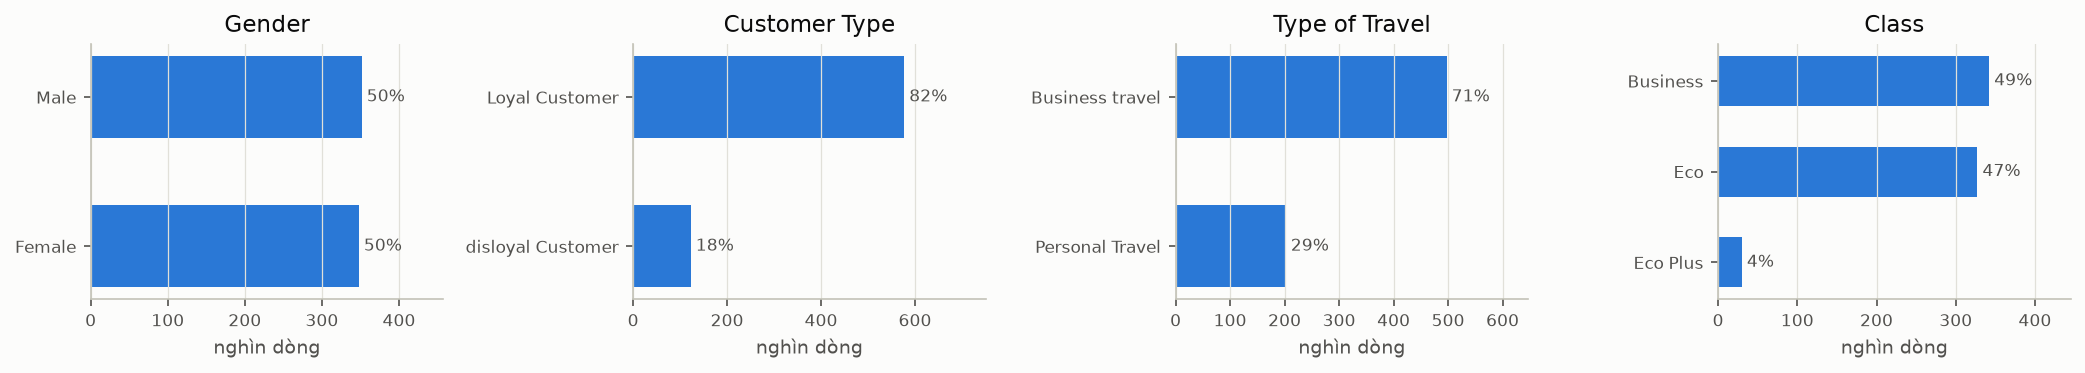

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 2.6))
for ax, col in zip(axes, CAT_COLS):
    vc = train[col].value_counts()
    ax.barh(vc.index.astype(str)[::-1], vc.values[::-1] / 1000, color=P.BLUE, height=0.55)
    for i, v in enumerate(vc.values[::-1]):
        ax.text(v / 1000, i, f" {v / len(train):.0%}", va="center", fontsize=8, color=P.INK_2)
    ax.set_title(col)
    ax.set_xlabel("nghìn dòng")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, vc.max() / 1000 * 1.3)
fig.tight_layout()
P.save(fig, "E1_01_category_counts")

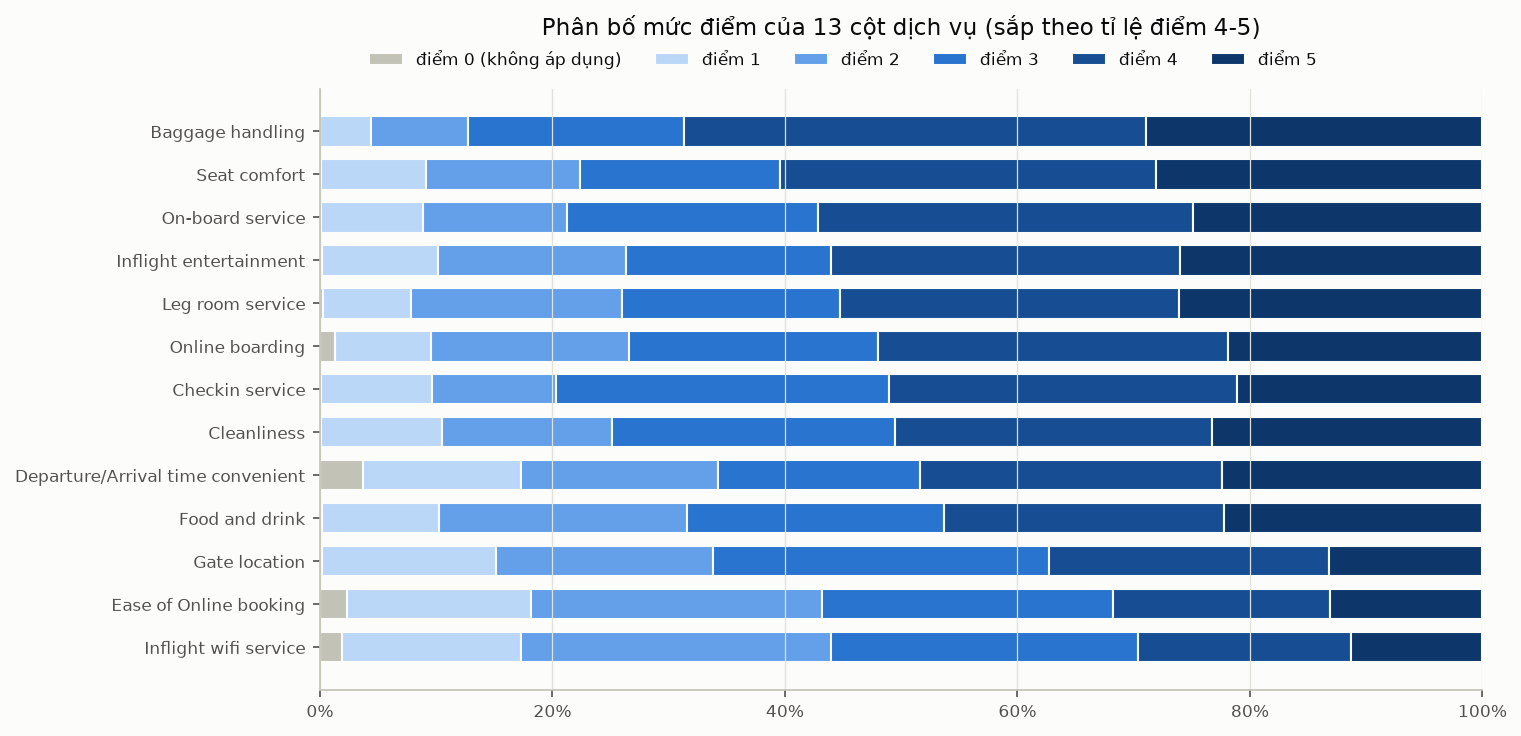

In [9]:
levels = range(6)
share = pd.DataFrame({c: train[c].value_counts(normalize=True).reindex(levels, fill_value=0) for c in SCORE_COLS}).T
share = share.loc[share[[4, 5]].sum(axis=1).sort_values().index]
colors = ["#c3c2b7"] + [P.SEQ(x) for x in np.linspace(0.05, 1, 5)]

fig, ax = plt.subplots(figsize=(10, 5.2))
left = np.zeros(len(share))
for lv, colr in zip(levels, colors):
    ax.barh(share.index, share[lv], left=left, color=colr, height=0.7, edgecolor=P.SURFACE, linewidth=1,
            label=f"điểm {lv}" + (" (không áp dụng)" if lv == 0 else ""))
    left += share[lv].values
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="y", visible=False)
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.45, 1.09))
ax.set_title("Phân bố mức điểm của 13 cột dịch vụ (sắp theo tỉ lệ điểm 4-5)", pad=26)
P.save(fig, "E1_02_score_distribution")

### 2.3 Biểu đồ: cột số (histogram, box-plot)

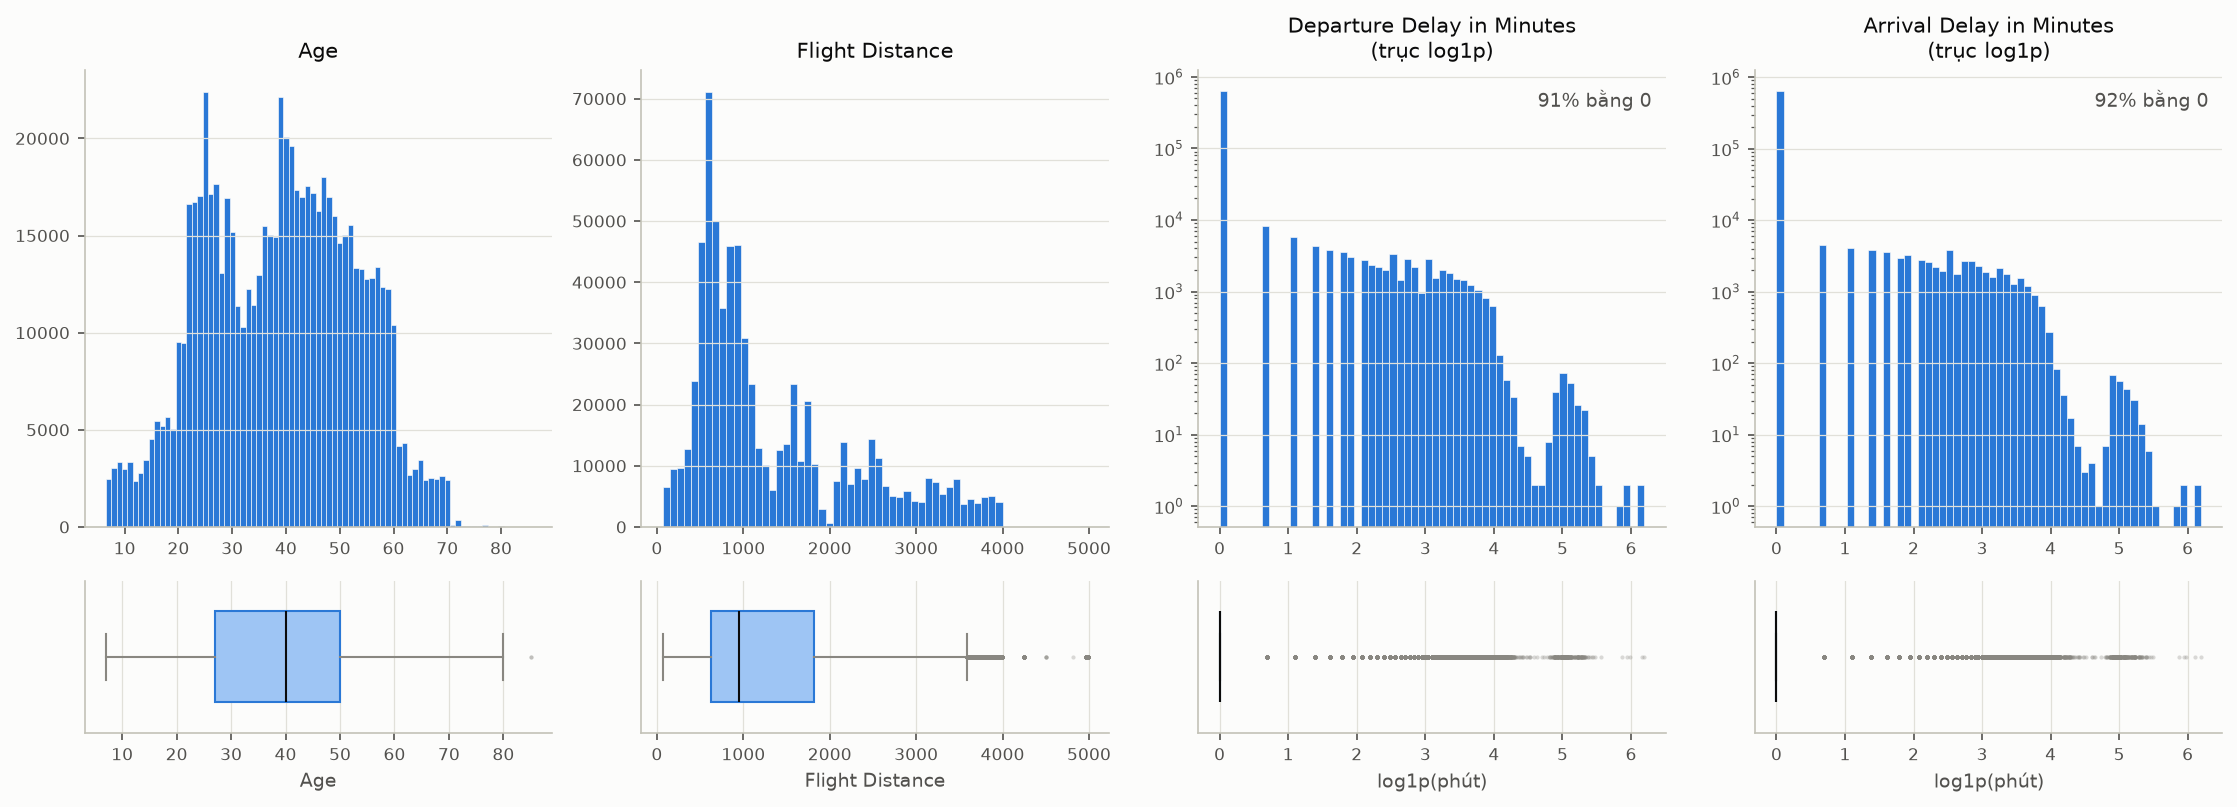

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(15, 5.5), gridspec_kw={"height_ratios": [3, 1]})
for j, col in enumerate(NUM_COLS):
    x = train[col].dropna()
    is_delay = "Delay" in col
    xs = np.log1p(x) if is_delay else x
    ax = axes[0, j]
    ax.hist(xs, bins=np.arange(6.5, 86.5, 1) if col == "Age" else 60, color=P.BLUE, edgecolor=P.SURFACE, linewidth=0.3)
    ax.set_title(col + ("\n(trục log1p)" if is_delay else ""), fontsize=10)
    if is_delay:
        ax.set_yscale("log")
        ax.text(0.97, 0.92, f"{(x == 0).mean():.0%} bằng 0", transform=ax.transAxes, ha="right", fontsize=9, color=P.INK_2)
    ax.grid(axis="x", visible=False)
    bx = axes[1, j]
    bx.boxplot(xs, orientation="horizontal", widths=0.6, showfliers=True, patch_artist=True,
               boxprops=dict(facecolor=P.BLUE_LIGHT, edgecolor=P.BLUE), medianprops=dict(color=P.INK),
               whiskerprops=dict(color=P.INK_3), capprops=dict(color=P.INK_3),
               flierprops=dict(marker=".", markersize=2, markeredgecolor=P.INK_3, alpha=0.3))
    bx.set_yticks([])
    bx.set_xlabel("log1p(phút)" if is_delay else col)
fig.tight_layout()
P.save(fig, "E1_03_numeric_distribution")

**Nhận xét mục 2**
- Category: `Gender` cân bằng; 82% là khách thân thiết; 71% đi công tác; `Class` gần như chỉ có Business (49%) và
  Eco (47%), Eco Plus hiếm (4,3%).
- Cột điểm: phần lớn điểm 3–5. Wifi, đặt vé online và vị trí cổng bị chấm thấp nhất. Điểm 0 ("không áp dụng")
  hiếm, nhiều nhất ở `Departure/Arrival time convenient` (3,7%), `Ease of Online booking` (2,3%), wifi (1,9%) và
  `Online boarding` (1,3%); `Baggage handling` không có điểm 0.
- `Age` 7–85, gần đối xứng (skew −0,05). `Flight Distance` lệch phải (skew 1,08), tập trung ở 500–1.000.
- Hai cột delay: 91% bằng 0, skew khoảng 13, đuôi dài tới 489 phút. Trên thang log1p vẫn lệch, nên mô hình nhạy
  với thang đo (LR, KNN) cần biến đổi log1p hoặc cắt ngưỡng.

## 3. Ngoại lệ và giá trị thiếu
### 3.1 Phát hiện ngoại lệ bằng IQR và z-score
IQR hợp với phân phối không chuẩn; z-score (|z| > 3) giả định gần chuẩn. So sánh hai cách trên 4 cột số.

In [11]:
rows = []
for col in NUM_COLS:
    x = train[col].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out_iqr = (x < lo) | (x > hi)
    z = (x - x.mean()) / x.std()
    out_z = z.abs() > 3
    rows.append({
        "cột": col, "Q1": q1, "Q3": q3, "IQR": iqr, "cận dưới": lo, "cận trên": hi,
        "ngoại lệ IQR": f"{out_iqr.mean():.2%}", "ngoại lệ |z|>3": f"{out_z.mean():.2%}",
        "tỉ lệ hài lòng ở ngoại lệ IQR": round(train.loc[x.index[out_iqr], TARGET].mean(), 3) if out_iqr.any() else np.nan,
        "max": x.max(),
    })
outliers = pd.DataFrame(rows).set_index("cột")
outliers.to_csv(RESULTS_DIR / "E1_outliers.csv")
outliers

,Q1,Q3,IQR,cận dưới,cận trên,ngoại lệ IQR,ngoại lệ |z|>3,tỉ lệ hài lòng ở ngoại lệ IQR,max
cột,,,,,,,,,
Age,27.0,50.0,23.0,-7.5,84.5,0.00%,0.00%,0.500,85.0
Flight Distance,631.0,1814.0,1183.0,-1143.5,3588.5,3.27%,0.03%,0.814,4983.0
Departure Delay in Minutes,0.0,0.0,0.0,0.0,0.0,9.22%,2.05%,0.400,489.0
Arrival Delay in Minutes,0.0,0.0,0.0,0.0,0.0,8.43%,2.12%,0.351,491.0


### 3.2 Giá trị thiếu: `Arrival Delay in Minutes`

In [12]:
dep, arr = train[DEP], train[ARR]
miss = arr.isna()
print(f"Thiếu: train {miss.sum()} dòng ({miss.mean():.3%}), test {test[ARR].isna().sum()} dòng")
print(f"Tỉ lệ hài lòng ở dòng thiếu: {train.loc[miss, TARGET].mean():.3f} (chung {BASE:.3f})")
print(f"Delay đi ở dòng thiếu: trung vị {dep[miss].median():.0f}, tỉ lệ = 0: {(dep[miss] == 0).mean():.1%}")
print(f"Tương quan Spearman delay đi và đến (dòng đủ): {dep.corr(arr, method='spearman'):.3f}")
print(f"Tỉ lệ dòng có delay đến = delay đi: {(arr == dep)[~miss].mean():.1%}")
print("=> Có thể điền delay đến bằng delay đi (hoặc mô hình hồi quy); so sánh các cách điền ở E2.")

Thiếu: train 292 dòng (0.042%), test 130 dòng
Tỉ lệ hài lòng ở dòng thiếu: 0.363 (chung 0.444)
Delay đi ở dòng thiếu: trung vị 0, tỉ lệ = 0: 72.3%
Tương quan Spearman delay đi và đến (dòng đủ): 0.472
Tỉ lệ dòng có delay đến = delay đi: 86.9%
=> Có thể điền delay đến bằng delay đi (hoặc mô hình hồi quy); so sánh các cách điền ở E2.


**Nhận xét mục 3**
- IQR **không dùng được** cho hai cột delay: Q1 = Q3 = 0 nên IQR = 0 và mọi delay khác 0 (9,2% / 8,4% số dòng) đều
  bị coi là ngoại lệ. Đó không phải lỗi dữ liệu mà là phân phối dồn về 0, nên không xoá dòng; xử lý bằng log1p,
  cắt ngưỡng hoặc cờ "có trễ" (so sánh ở E2). z-score (|z| > 3) chỉ bắt khoảng 2% nhưng cũng giả định phân phối
  chuẩn, vốn không đúng ở đây.
- `Age` không có ngoại lệ. `Flight Distance` có 3,3% vượt cận trên 3.588 theo IQR, nhưng đó là chuyến bay dài thật
  và có tỉ lệ hài lòng 81% (cao hơn hẳn mức chung 44%), tức mang thông tin, không nên xoá.
- Giá trị thiếu chỉ 0,04%. Tỉ lệ hài lòng ở các dòng thiếu là 36%, hơi thấp hơn mức chung, nhưng 292 dòng là quá ít
  để kết luận. Ở 86,9% dòng đủ dữ liệu, delay đến bằng đúng delay đi, nên điền delay đến bằng delay đi là hợp lý.
  E2 so sánh: điền median, điền bằng delay đi, thêm cờ thiếu.

## 4. Phân tích hai biến: từng cột với nhãn
### 4.1 Category và nhãn

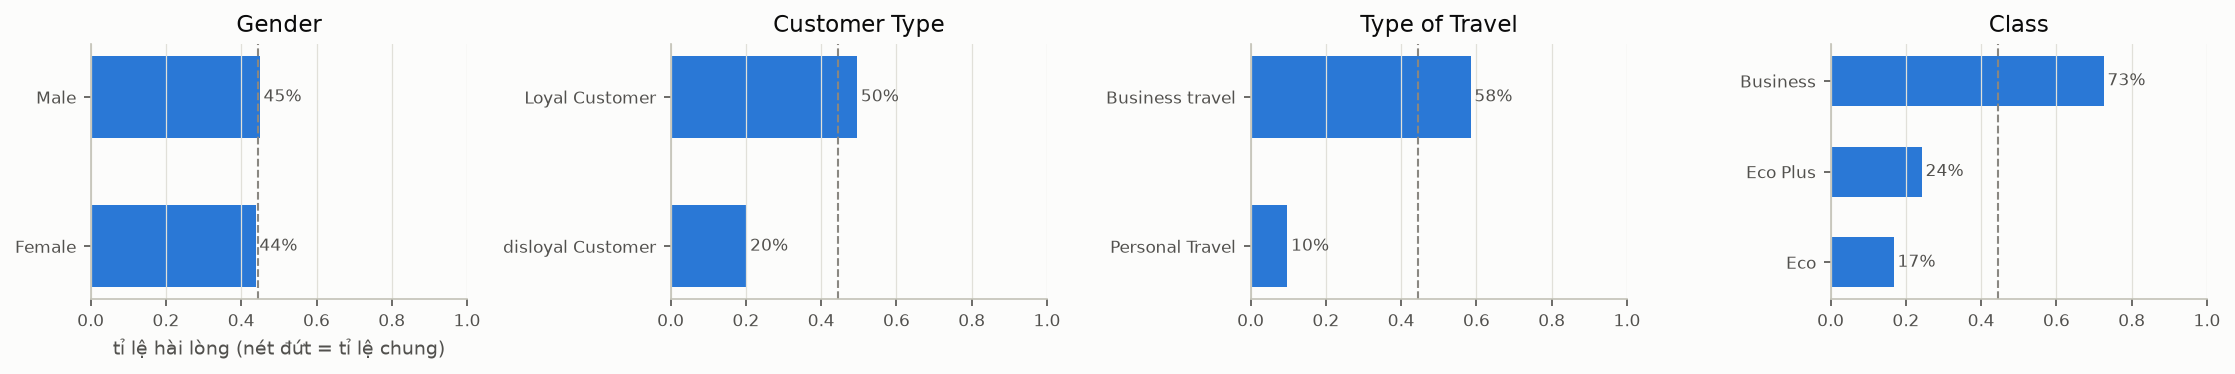

In [13]:
def rate_table(col, df=train):
    return df.groupby(col, observed=True)[TARGET].agg(rate="mean", n="size")


fig, axes = plt.subplots(1, 4, figsize=(15, 2.6))
for ax, col in zip(axes, CAT_COLS):
    t = rate_table(col).sort_values("rate")
    ax.barh(t.index.astype(str), t["rate"], color=P.BLUE, height=0.55)
    ax.axvline(BASE, color=P.REF, lw=1, ls="--")
    for i, r in enumerate(t["rate"]):
        ax.text(r + 0.01, i, f"{r:.0%}", va="center", fontsize=8, color=P.INK_2)
    ax.set_xlim(0, 1)
    ax.set_title(col)
    ax.grid(axis="y", visible=False)
axes[0].set_xlabel("tỉ lệ hài lòng (nét đứt = tỉ lệ chung)")
fig.tight_layout()
P.save(fig, "E1_04_category_rate")

### 4.2 Điểm dịch vụ và nhãn

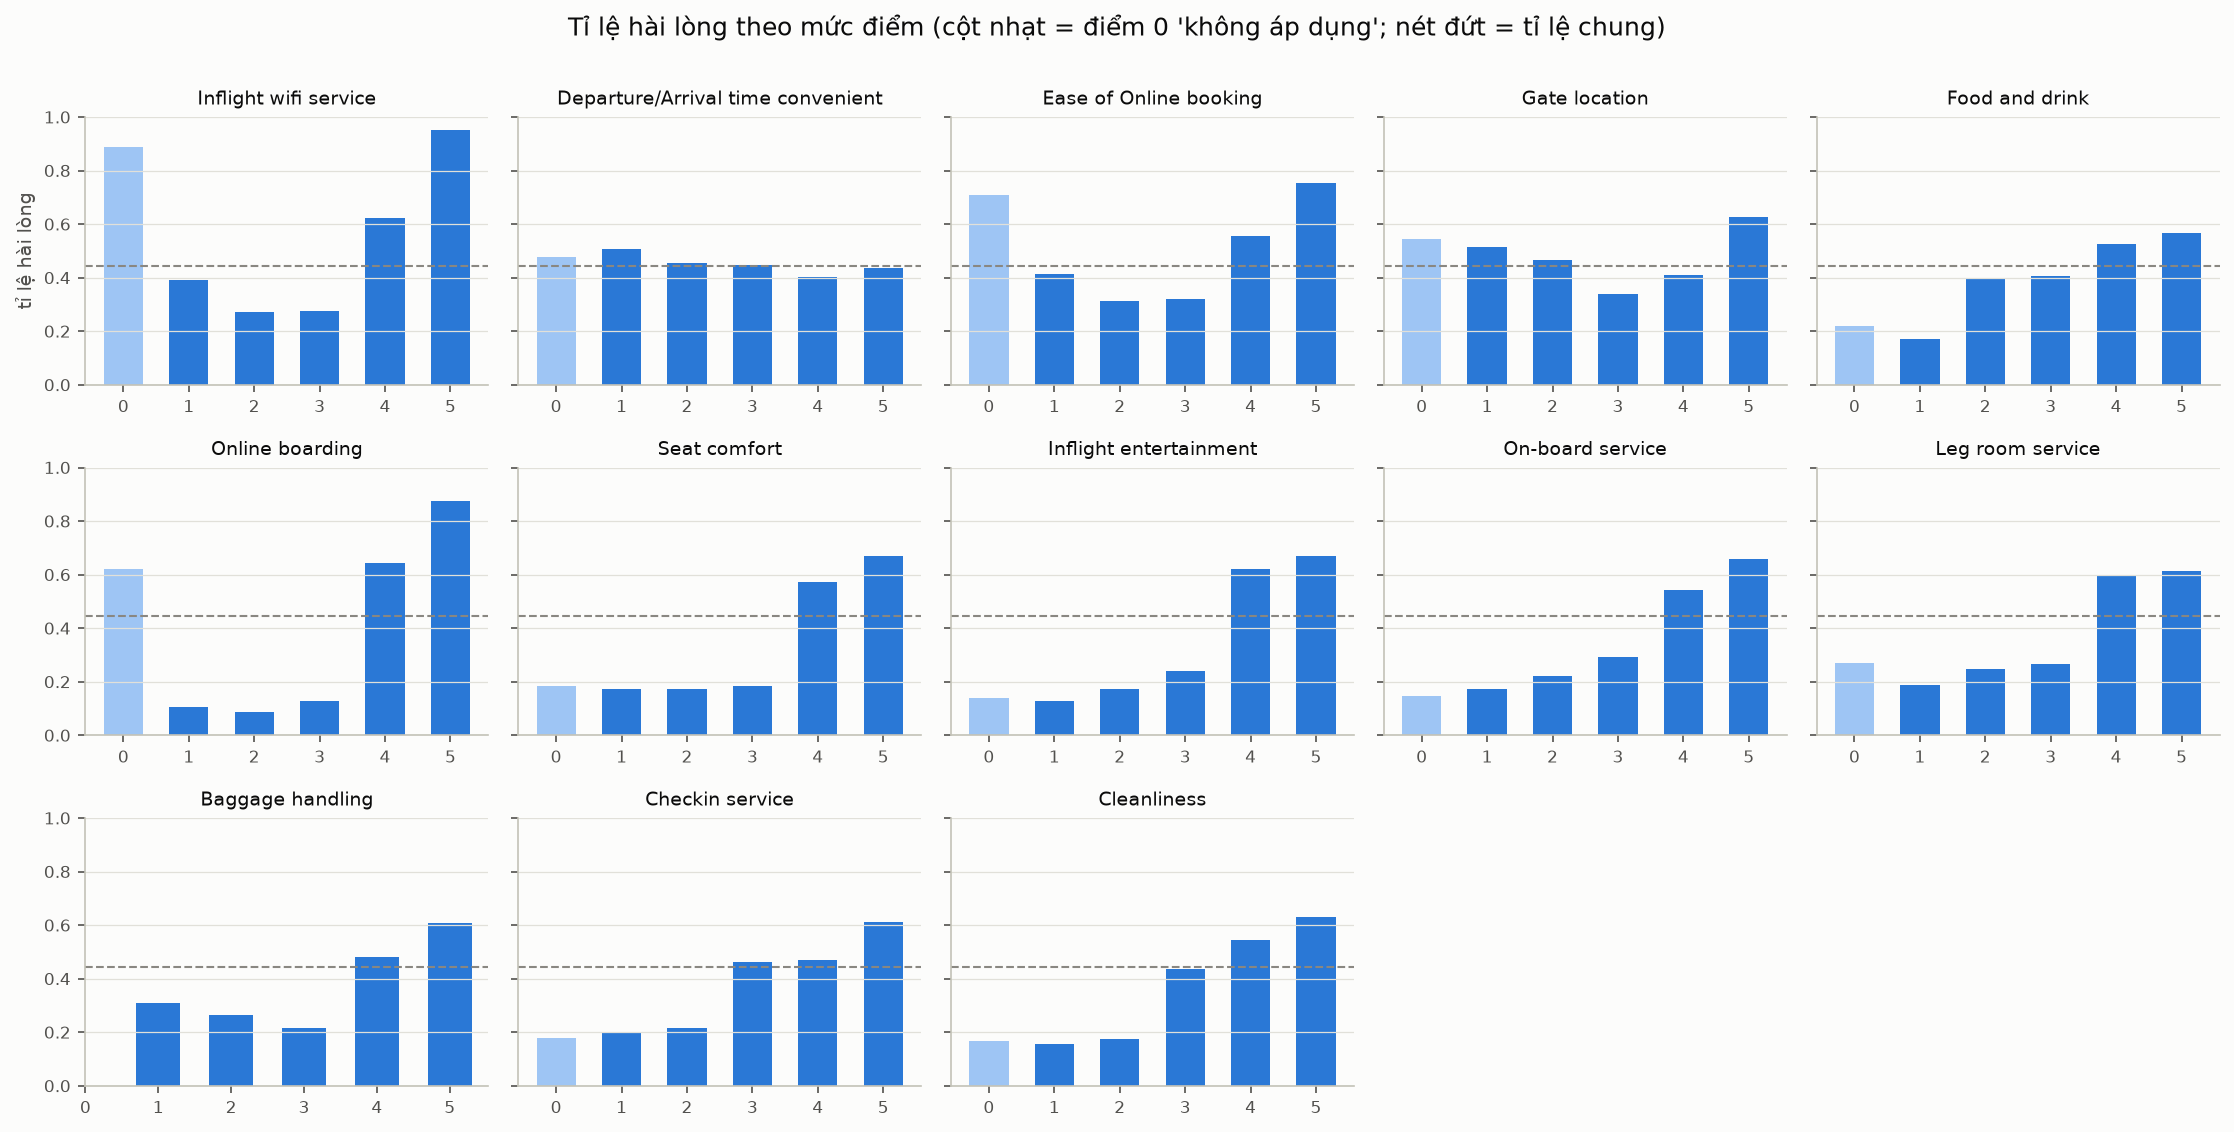

,tỉ lệ @0,số dòng @0,tỉ lệ @1,tỉ lệ @5,@5 - @1,tăng đều 1→5
Online boarding,0.620422,9147,0.105282,0.87511,0.769827,False
Inflight wifi service,0.887345,13102,0.390666,0.95036,0.559694,False
Inflight entertainment,0.140196,1020,0.126663,0.67109,0.544427,True
Seat comfort,0.183771,838,0.173626,0.671106,0.49748,False
On-board service,0.147316,801,0.174498,0.656603,0.482105,True
Cleanliness,0.168254,945,0.154831,0.630477,0.475646,True
Leg room service,0.269935,1693,0.188684,0.615094,0.426409,True
Checkin service,0.178687,929,0.199239,0.610308,0.41107,True
Food and drink,0.218935,1014,0.170678,0.565498,0.39482,True
Ease of Online booking,0.707584,16073,0.414589,0.754319,0.33973,False


In [14]:
fig, axes = plt.subplots(3, 5, figsize=(15, 7.5), sharey=True)
score_tab = {}
for ax, col in zip(axes.flat, SCORE_COLS):
    t = rate_table(col)
    score_tab[col] = t
    ax.bar(t.index, t["rate"], color=[P.BLUE_LIGHT if s == 0 else P.BLUE for s in t.index], width=0.6)
    ax.axhline(BASE, color=P.REF, lw=1, ls="--")
    ax.set_title(col, fontsize=9)
    ax.set_xticks(range(6))
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
for ax in axes.flat[len(SCORE_COLS):]:
    ax.axis("off")
axes[0, 0].set_ylabel("tỉ lệ hài lòng")
fig.suptitle("Tỉ lệ hài lòng theo mức điểm (cột nhạt = điểm 0 'không áp dụng'; nét đứt = tỉ lệ chung)", y=1.0)
fig.tight_layout()
P.save(fig, "E1_05_score_rate")

score_summary = pd.DataFrame({
    col: {"tỉ lệ @0": t["rate"].get(0, np.nan), "số dòng @0": t["n"].get(0, 0),
          "tỉ lệ @1": t["rate"].get(1), "tỉ lệ @5": t["rate"].get(5),
          "@5 - @1": t["rate"].get(5) - t["rate"].get(1),
          "tăng đều 1→5": bool(np.all(np.diff(t["rate"].reindex(range(1, 6)).values) > 0))}
    for col, t in score_tab.items()
}).T.sort_values("@5 - @1", ascending=False)
score_summary.to_csv(RESULTS_DIR / "E1_score_rate.csv")
score_summary

### 4.3 Cột số và nhãn

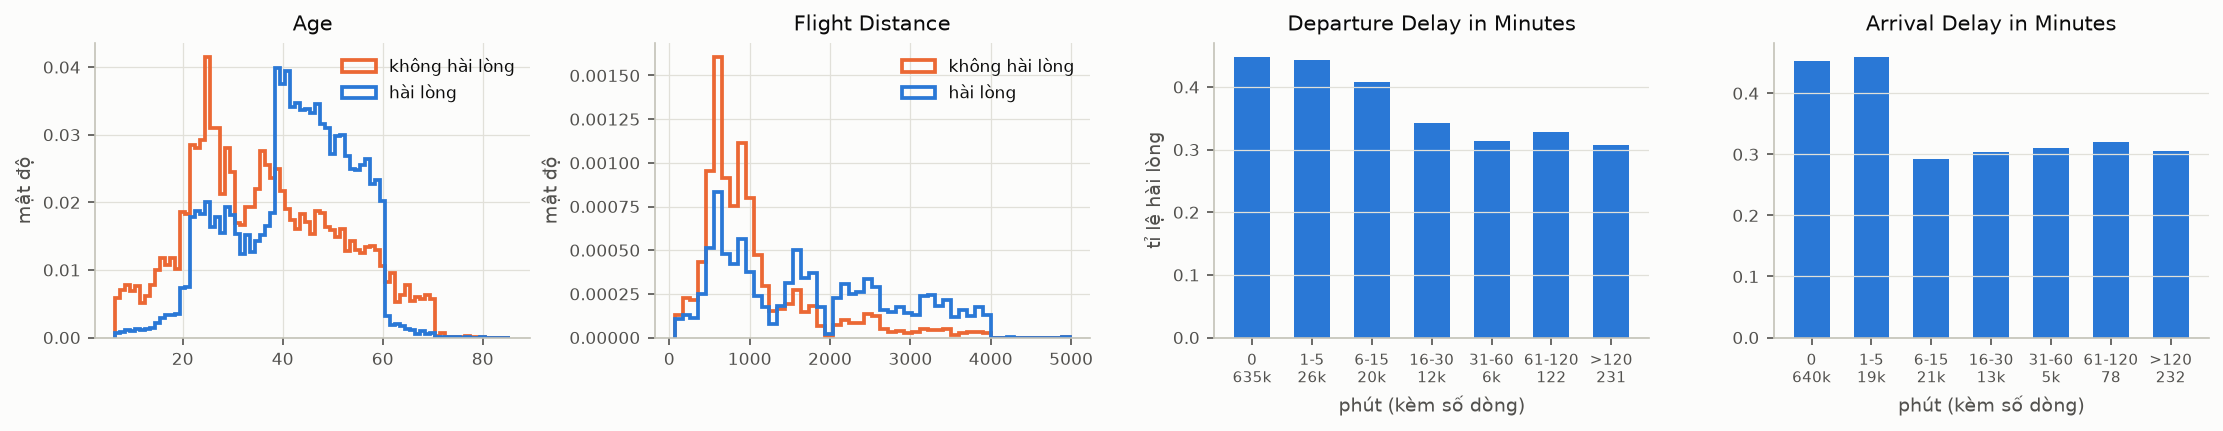

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, col in zip(axes, NUM_COLS):
    is_delay = "Delay" in col
    x = train[col]
    if is_delay:
        bins = [-1, 0, 5, 15, 30, 60, 120, 10_000]
        labels = ["0", "1-5", "6-15", "16-30", "31-60", "61-120", ">120"]
        g = train.groupby(pd.cut(x, bins, labels=labels), observed=True)[TARGET].agg(["mean", "size"])
        ax.bar(range(len(g)), g["mean"], color=P.BLUE, width=0.6)
        ax.set_xticks(range(len(g)), [f"{l}\n{n / 1000:.0f}k" if n >= 1000 else f"{l}\n{n}" for l, n in zip(g.index, g["size"])], fontsize=7)
        ax.set_xlabel("phút (kèm số dòng)")
        ax.grid(axis="x", visible=False)
    else:
        for lab, colr, name in [(0, P.NEG, "không hài lòng"), (1, P.POS, "hài lòng")]:
            ax.hist(x[y == lab], bins=np.arange(6.5, 86.5, 1) if col == "Age" else 50, density=True, histtype="step", color=colr, lw=1.8, label=name)
        ax.set_ylabel("mật độ")
        ax.legend()
    ax.set_title(col, fontsize=10)
axes[2].set_ylabel("tỉ lệ hài lòng")
fig.tight_layout()
P.save(fig, "E1_06_numeric_vs_target")

### 4.4 Độ mạnh của từng cột khi đứng riêng (AUC một cột)
Category mã hoá bằng tỉ lệ hài lòng của từng giá trị; cột số và điểm dùng trực tiếp. AUC < 0,5 thì lấy 1 − AUC
và ghi chiều (−).

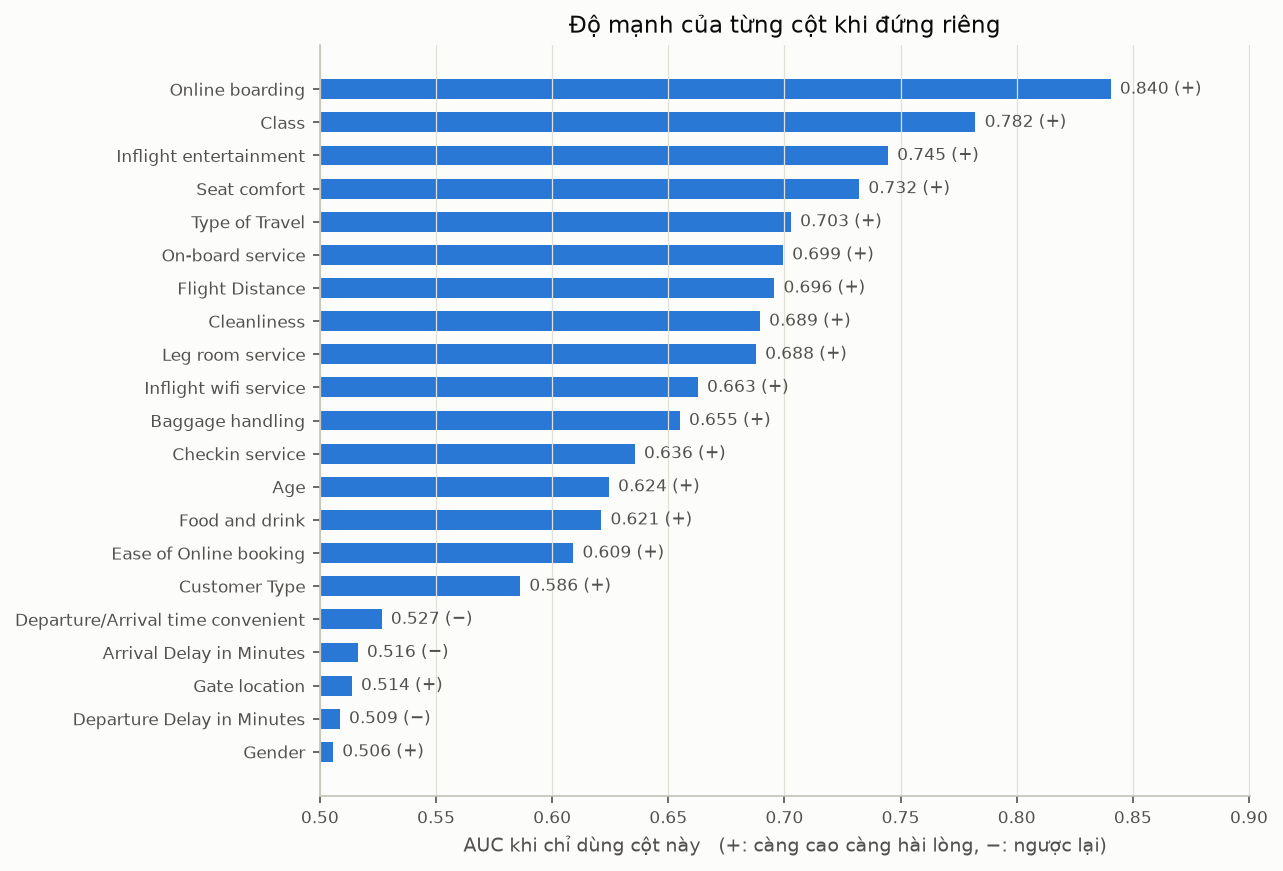

In [16]:
rows = []
for col in FEATURES:
    x = train[col]
    if col in CAT_COLS:
        x = x.map(train.groupby(col)[TARGET].mean())
    x = x.fillna(x.median())
    auc = roc_auc_score(y, x)
    rows.append({"feature": col, "auc": max(auc, 1 - auc), "chiều": "+" if auc >= 0.5 else "−"})
uni = pd.DataFrame(rows).sort_values("auc").reset_index(drop=True)
uni.sort_values("auc", ascending=False).to_csv(RESULTS_DIR / "E1_univariate_auc.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(uni["feature"], uni["auc"] - 0.5, left=0.5, color=P.BLUE, height=0.6)
for i, (a, s) in enumerate(zip(uni["auc"], uni["chiều"])):
    ax.text(a + 0.004, i, f"{a:.3f} ({s})", va="center", fontsize=8, color=P.INK_2)
ax.set_xlim(0.5, uni["auc"].max() + 0.06)
ax.set_xlabel("AUC khi chỉ dùng cột này   (+: càng cao càng hài lòng, −: ngược lại)")
ax.set_title("Độ mạnh của từng cột khi đứng riêng")
ax.grid(axis="y", visible=False)
P.save(fig, "E1_07_univariate_auc")

**Nhận xét mục 4**
- Cột điểm: tỉ lệ hài lòng nhìn chung tăng theo điểm. Mạnh nhất là `Online boarding`: 11% ở điểm 1, 88% ở điểm 5.
- **Điểm 0 hành xử khác hẳn "điểm thấp nhất"**: wifi = 0 có 89% hài lòng (13 nghìn dòng), đặt vé online = 0 có
  71%, online boarding = 0 có 62%. Riêng wifi, điểm 0 (89%) cao hơn mọi mức 1–4 và chỉ đứng sau điểm 5 (95%).
  Vì vậy không nên coi 0 là số nhỏ nhất của thang đo; cần mã hoá riêng (one-hot hoặc cờ điểm 0) cho mô hình
  tuyến tính.
- Chỉ 6/13 cột có tỉ lệ tăng đều từ điểm 1 đến 5; `Departure/Arrival time convenient` còn giảm nhẹ (51% → 44%).
  Quan hệ không đơn điệu này mô hình tuyến tính không học được nếu để điểm dạng số.
- `Age`: khách hài lòng tập trung ở 40–60 tuổi, khách không hài lòng nhiều ở dưới 30 và trên 60, quan hệ hình
  chữ ∩, không tuyến tính. `Flight Distance`: chuyến trên khoảng 1.500 có tỉ lệ hài lòng cao hơn.
- Delay: tỉ lệ hài lòng giảm từ 45% (không trễ) xuống khoảng 30% khi trễ trên 15 phút, nhưng 91% dòng không trễ nên
  AUC của cả cột chỉ 0,51.
- AUC một cột: mạnh nhất `Online boarding` 0,840, `Class` 0,782, `Inflight entertainment` 0,745, `Seat comfort`
  0,732, `Type of Travel` 0,703. Yếu nhất `Gender` 0,506, hai cột delay 0,509 / 0,516, `Gate location` 0,514,
  `Departure/Arrival time convenient` 0,527. Yếu khi đứng riêng chưa chắc vô dụng khi kết hợp, nên việc bỏ cột
  được quyết bằng CV ở E2 (chọn đặc trưng).

## 5. Tương quan và tương tác
### 5.1 Ma trận tương quan (Spearman, vì điểm là thứ bậc và delay lệch mạnh)

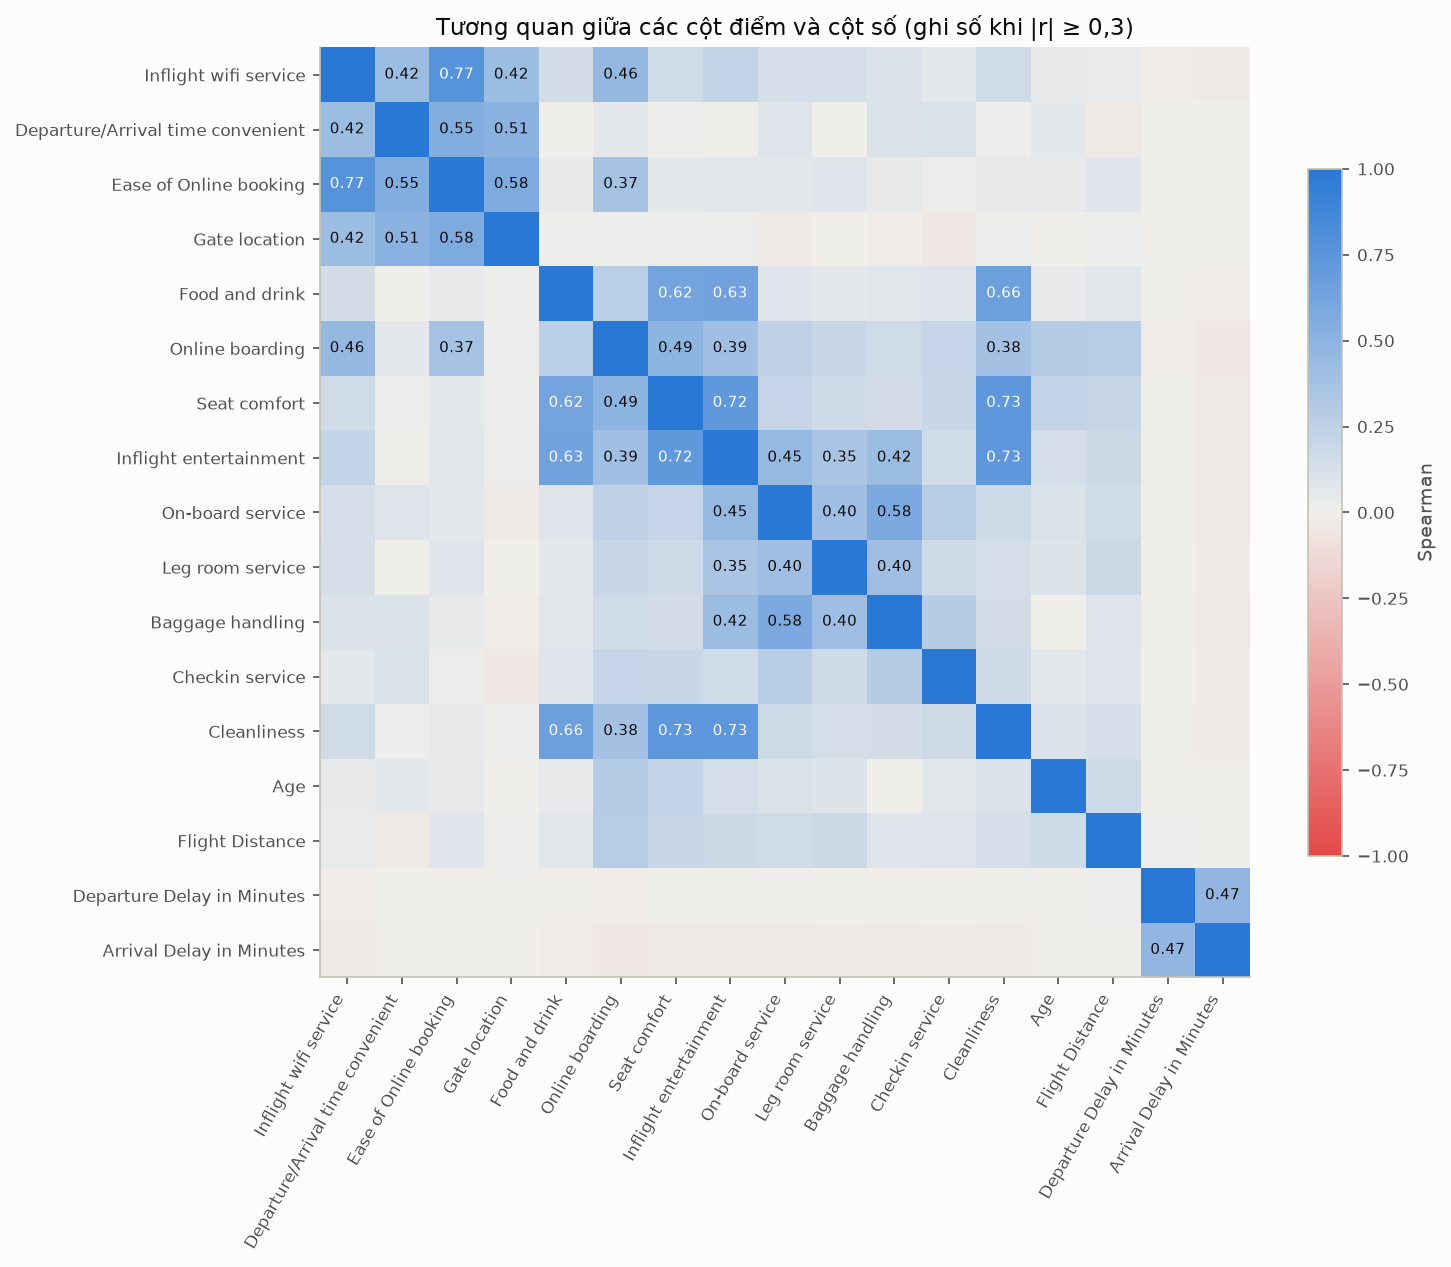

,level_0,level_1,r,abs_r
1,Inflight wifi service,Ease of Online booking,0.770,0.770
86,Seat comfort,Cleanliness,0.733,0.733
95,Inflight entertainment,Cleanliness,0.727,0.727
81,Seat comfort,Inflight entertainment,0.723,0.723
65,Food and drink,Cleanliness,0.657,0.657
60,Food and drink,Inflight entertainment,0.633,0.633
59,Food and drink,Seat comfort,0.620,0.620
101,On-board service,Baggage handling,0.581,0.581
31,Ease of Online booking,Gate location,0.577,0.577
16,Departure/Arrival time convenient,Ease of Online booking,0.549,0.549


In [17]:
cols = SCORE_COLS + NUM_COLS
corr = train[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap=P.DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right")
ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.values[i, j]
        if i != j and abs(v) >= 0.3:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color=P.SURFACE if abs(v) >= 0.6 else P.INK)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman")
ax.set_title("Tương quan giữa các cột điểm và cột số (ghi số khi |r| ≥ 0,3)")
P.save(fig, "E1_08_correlation")

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("r").reset_index()
         .assign(abs_r=lambda d: d["r"].abs()).sort_values("abs_r", ascending=False))
pairs.head(10).round(3)

### 5.2 Tương tác giữa các cột category
Tỉ lệ hài lòng theo từng cặp giá trị. Nếu hai cột tác động độc lập thì các hàng trong bảng sẽ song song nhau.

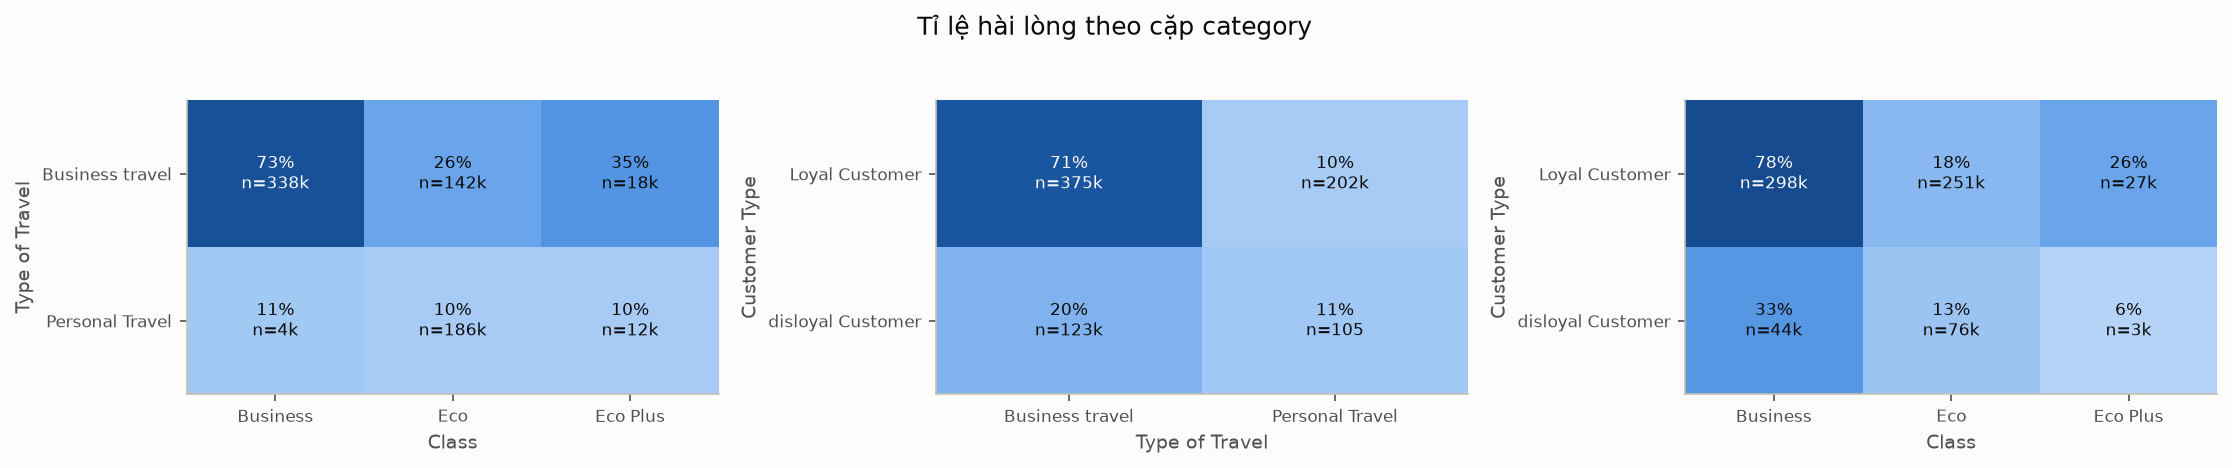

In [18]:
pairs_cat = [("Type of Travel", "Class"), ("Customer Type", "Type of Travel"), ("Customer Type", "Class")]
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, (a, b) in zip(axes, pairs_cat):
    rate = train.pivot_table(index=a, columns=b, values=TARGET, aggfunc="mean")
    n = train.pivot_table(index=a, columns=b, values=TARGET, aggfunc="size")
    ax.imshow(rate.values, cmap=P.SEQ, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(rate.shape[1]), rate.columns)
    ax.set_yticks(range(rate.shape[0]), rate.index)
    ax.set_xlabel(b)
    ax.set_ylabel(a)
    ax.grid(False)
    for i in range(rate.shape[0]):
        for j in range(rate.shape[1]):
            v = rate.values[i, j]
            nn = n.values[i, j]
            ax.text(j, i, f"{v:.0%}\nn={nn / 1000:.0f}k" if nn >= 1000 else f"{v:.0%}\nn={nn:.0f}", ha="center", va="center", fontsize=8,
                    color=P.SURFACE if v > 0.55 else P.INK)
fig.suptitle("Tỉ lệ hài lòng theo cặp category", y=1.03)
fig.tight_layout()
P.save(fig, "E1_09_category_interaction")

**Nhận xét mục 5**
- Tương quan mạnh nhất: wifi và đặt vé online (0,77). Có hai cụm cột: "trải nghiệm trên máy bay" (ghế, vệ sinh,
  giải trí, đồ ăn; 0,62–0,73) và "đặt vé, sân bay" (wifi, đặt vé, vị trí cổng, giờ bay; 0,55–0,77). Không cặp nào
  vượt 0,8 nên không có cột trùng lặp hẳn, nhưng đa cộng tuyến ở mức vừa: mô hình tuyến tính nên có chính quy hoá
  (Ridge / L1, Bài 07).
- Hai cột delay tương quan Spearman 0,47: thấp vì phần lớn bằng 0 và các giá trị khác 0 lệch nhau nhiều.
- **Tương tác mạnh**: khách công tác ngồi Business hài lòng 73%, còn khách đi việc riêng chỉ khoảng 10% bất kể hạng
  ghế, tức `Class` chỉ có tác dụng với khách công tác. Tương tự, khách thân thiết đi công tác 71% so với đi việc
  riêng 10%. Ô "không thân thiết × đi việc riêng" chỉ có 105 dòng. Mô hình tuyến tính cần feature ghép
  (ví dụ `Type of Travel` × `Class`) để học được điều này; mô hình cây tự tách được (kiểm chứng ở E2, E3).

## 6. Phân tích đa biến không giám sát (Bài 06)
### 6.1 PCA
Chuẩn hoá (z-score) 13 cột điểm + 4 cột số (delay lấy log1p) + one-hot 4 cột category, rồi PCA.

In [19]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


def numeric_matrix(df):
    X = df[SCORE_COLS + NUM_COLS].copy()
    X[ARR] = X[ARR].fillna(X[DEP])
    for c in (DEP, ARR):
        X[c] = np.log1p(X[c])
    return pd.concat([X, pd.get_dummies(df[CAT_COLS], drop_first=True, dtype=float)], axis=1)


Xn = numeric_matrix(train)
Z = StandardScaler().fit_transform(Xn)
pca = PCA().fit(Z)
evr = pca.explained_variance_ratio_
print("Phương sai giải thích (5 thành phần đầu):", np.round(evr[:5], 3), "| tích luỹ:", np.round(np.cumsum(evr)[:5], 3))
print(f"Cần {np.searchsorted(np.cumsum(evr), 0.9) + 1}/{len(evr)} thành phần để giữ 90% phương sai")

pc = pca.transform(Z)[:, :2]
auc_pc1 = roc_auc_score(y, pc[:, 0])
print(f"AUC của riêng PC1: {max(auc_pc1, 1 - auc_pc1):.4f}")
load = pd.DataFrame(pca.components_[:2].T, index=Xn.columns, columns=["PC1", "PC2"])
load.reindex(load["PC1"].abs().sort_values(ascending=False).index).head(8).round(3)

Phương sai giải thích (5 thành phần đầu): [0.204 0.117 0.087 0.081 0.074] | tích luỹ: [0.204 0.321 0.408 0.489 0.564]
Cần 14/22 thành phần để giữ 90% phương sai


AUC của riêng PC1: 0.8802


,PC1,PC2
Inflight entertainment,0.386,-0.153
Seat comfort,0.365,-0.151
Cleanliness,0.338,-0.154
Online boarding,0.326,0.088
Food and drink,0.282,-0.139
Class_Eco,-0.253,0.083
On-board service,0.232,-0.054
Inflight wifi service,0.220,0.432


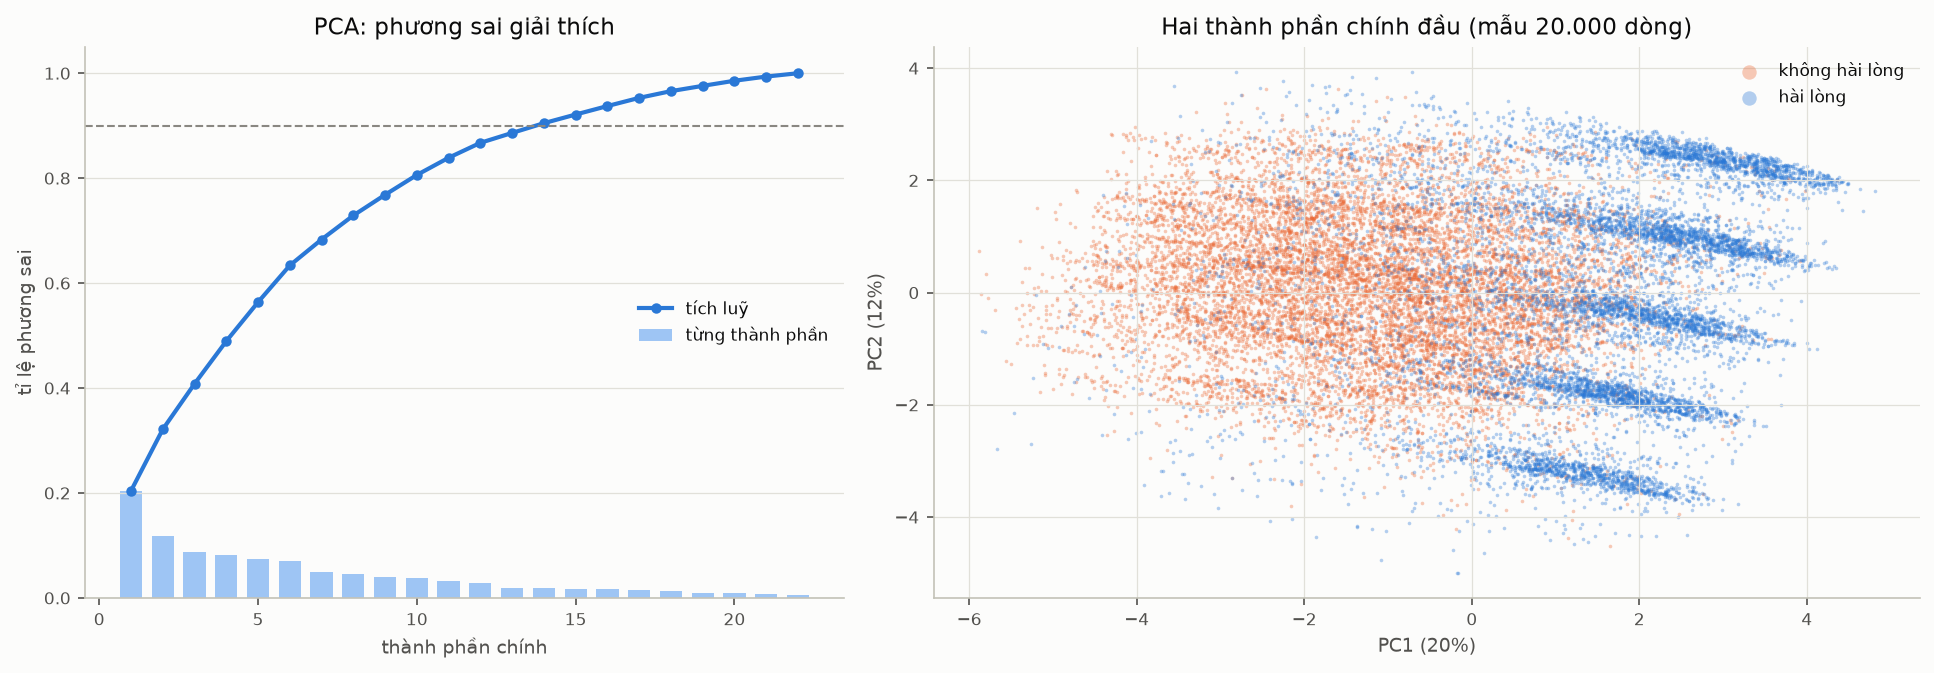

In [20]:
rng = np.random.default_rng(42)
idx = rng.choice(len(train), 20_000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})
k = np.arange(1, len(evr) + 1)
axes[0].bar(k, evr, color=P.BLUE_LIGHT, width=0.7, label="từng thành phần")
axes[0].plot(k, np.cumsum(evr), color=P.BLUE, marker="o", ms=4, label="tích luỹ")
axes[0].axhline(0.9, color=P.REF, ls="--", lw=1)
axes[0].set_xlabel("thành phần chính")
axes[0].set_ylabel("tỉ lệ phương sai")
axes[0].set_title("PCA: phương sai giải thích")
axes[0].legend(loc="center right")
axes[0].grid(axis="x", visible=False)
for lab, colr, name in [(0, P.NEG, "không hài lòng"), (1, P.POS, "hài lòng")]:
    m = y[idx] == lab
    axes[1].scatter(pc[idx][m, 0], pc[idx][m, 1], s=3, alpha=0.35, color=colr, label=name, linewidths=0)
axes[1].set_xlabel(f"PC1 ({evr[0]:.0%})")
axes[1].set_ylabel(f"PC2 ({evr[1]:.0%})")
axes[1].set_title("Hai thành phần chính đầu (mẫu 20.000 dòng)")
axes[1].legend(markerscale=4)
fig.tight_layout()
P.save(fig, "E1_10_pca")

### 6.2 t-SNE (mẫu 6.000 dòng)

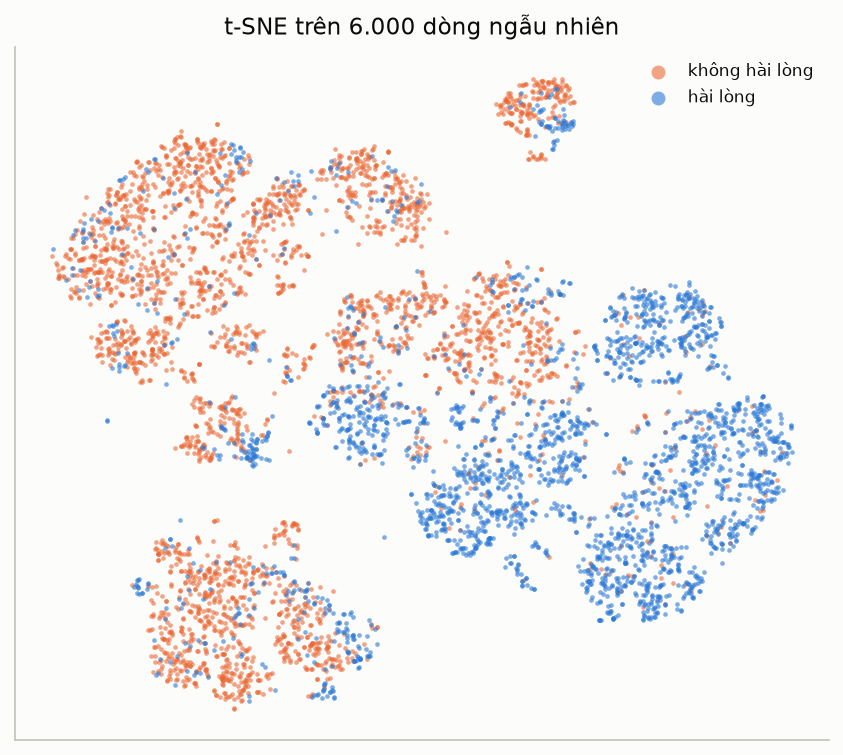

In [21]:
from sklearn.manifold import TSNE

idx_t = rng.choice(len(train), 6_000, replace=False)
emb = TSNE(n_components=2, perplexity=40, init="pca", random_state=42).fit_transform(Z[idx_t])
fig, ax = plt.subplots(figsize=(7, 6))
for lab, colr, name in [(0, P.NEG, "không hài lòng"), (1, P.POS, "hài lòng")]:
    m = y[idx_t] == lab
    ax.scatter(emb[m, 0], emb[m, 1], s=5, alpha=0.6, color=colr, label=name, linewidths=0)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("t-SNE trên 6.000 dòng ngẫu nhiên")
ax.legend(markerscale=3)
P.save(fig, "E1_11_tsne")

### 6.3 Gom cụm KMeans trên 13 cột điểm
Gom hành khách theo "hồ sơ chấm điểm", xem tỉ lệ hài lòng từng cụm khác nhau đến đâu (gợi ý đặc trưng cụm ở E2).

In [22]:
from sklearn.cluster import KMeans

Zs = StandardScaler().fit_transform(train[SCORE_COLS])
inertia = {kk: KMeans(kk, n_init=3, random_state=42).fit(Zs[idx]).inertia_ for kk in range(2, 11)}
km = KMeans(6, n_init=5, random_state=42).fit(Zs)
train_cluster = km.labels_
clu = (train.assign(cụm=train_cluster).groupby("cụm")
       .agg(số_dòng=(TARGET, "size"), tỉ_lệ_hài_lòng=(TARGET, "mean"),
            TB_online_boarding=("Online boarding", "mean"), TB_wifi=("Inflight wifi service", "mean"),
            TB_entertainment=("Inflight entertainment", "mean"), TB_seat=("Seat comfort", "mean"))
       .sort_values("tỉ_lệ_hài_lòng"))
auc_clu = roc_auc_score(y, pd.Series(train_cluster).map(clu["tỉ_lệ_hài_lòng"]))
print("Inertia theo k (mẫu 20k):", {kk: round(v) for kk, v in inertia.items()})
print(f"AUC khi chỉ dùng mã cụm (k=6): {auc_clu:.4f}")
clu.round(3)

Inertia theo k (mẫu 20k): {2: 202055, 3: 174514, 4: 159594, 5: 150636, 6: 143255, 7: 137329, 8: 132332, 9: 127942, 10: 124197}
AUC khi chỉ dùng mã cụm (k=6): 0.8537


,số_dòng,tỉ_lệ_hài_lòng,TB_online_boarding,TB_wifi,TB_entertainment,TB_seat
cụm,,,,,,
1,95754,0.098,2.107,1.893,2.024,2.217
3,87906,0.105,2.010,1.925,4.371,4.262
5,109247,0.172,2.676,2.738,2.033,1.939
4,108629,0.260,3.661,3.005,2.933,3.691
2,188535,0.802,4.310,4.058,4.369,4.345
0,109564,0.854,4.314,1.853,4.328,4.363


**Nhận xét mục 6**
- PCA: PC1 giữ 20% phương sai, PC2 12%; cần 14/22 thành phần mới giữ 90%, tức dữ liệu không nén mạnh được, giảm
  chiều để huấn luyện không hứa hẹn. PC1 là trục "chất lượng trải nghiệm" (giải trí, ghế, vệ sinh, online boarding
  mang dấu dương; hạng Eco mang dấu âm). **Riêng PC1 đạt AUC 0,880**, cao hơn mọi cột đơn lẻ (cao nhất 0,840): tổng
  hợp nhiều cột điểm có ích, gợi ý feature tổng / trung bình điểm ở E2. PC2 chủ yếu là wifi.
- Trên mặt phẳng PC1–PC2, hai lớp tách dần theo PC1 nhưng chồng lấn nhiều ở giữa. Các "sọc" là do điểm là số rời rạc.
- t-SNE: nhiều cụm gần như chỉ một lớp, xen kẽ vài vùng trộn lẫn. Biên phân lớp phi tuyến và cục bộ, phù hợp với
  mô hình cây / boosting hơn mô hình tuyến tính (kiểm chứng ở E3).
- KMeans 6 cụm trên 13 cột điểm: tỉ lệ hài lòng từ 10% đến 85%, riêng mã cụm đã đạt AUC 0,854. Hai cụm đáng chú ý:
  cụm wifi thấp (1,9) nhưng online boarding, giải trí, ghế cao vẫn có 85% hài lòng; ngược lại cụm giải trí và ghế
  cao (4,4 / 4,3) nhưng online boarding thấp (2,0) chỉ có 10%. Online boarding quan trọng hơn tiện nghi trên máy
  bay. Inertia giảm đều theo k, không có "khuỷu tay" rõ, nên k = 6 là lựa chọn minh hoạ; đặc trưng cụm được thử ở E2.

## 7. Train và test có cùng phân phối không? (adversarial validation)
Gắn nhãn 0 cho dòng train, 1 cho dòng test, huấn luyện LightGBM phân biệt hai bên (5 fold). AUC ≈ 0,5 nghĩa là
không phân biệt được, tức hai tập cùng phân phối và điểm CV đáng tin cho test.

In [23]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold

both = pd.concat([train[FEATURES], test[FEATURES]], ignore_index=True)
for c in CAT_COLS:
    both[c] = both[c].astype("category")
is_test = np.r_[np.zeros(len(train)), np.ones(len(test))]
pred = np.zeros(len(both))
imp = pd.Series(0.0, index=FEATURES)
for tr, va in StratifiedKFold(5, shuffle=True, random_state=42).split(both, is_test):
    m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, num_leaves=63, n_jobs=6, verbose=-1, random_state=42)
    m.fit(both.iloc[tr], is_test[tr])
    pred[va] = m.predict_proba(both.iloc[va])[:, 1]
    imp += pd.Series(m.booster_.feature_importance("gain"), index=FEATURES) / 5
adv_auc = roc_auc_score(is_test, pred)
print(f"Adversarial AUC = {adv_auc:.4f}")

ks = pd.DataFrame({c: ks_2samp(train[c].dropna(), test[c].dropna()).statistic for c in NUM_COLS + SCORE_COLS},
                  index=["KS train-test"]).T
ks["gain (adversarial)"] = (imp / imp.sum()).round(3)
ks.sort_values("KS train-test", ascending=False).head(6).round(4)

Adversarial AUC = 0.4995


,KS train-test,gain (adversarial)
Cleanliness,0.0027,0.030
Food and drink,0.0022,0.036
On-board service,0.0022,0.042
Leg room service,0.0016,0.047
Baggage handling,0.0015,0.038
Departure/Arrival time convenient,0.0014,0.041


## 8. Dữ liệu tổng hợp và dữ liệu gốc
Dữ liệu cuộc thi được sinh từ bộ gốc 129 nghìn dòng. So sánh để biết có nên dùng dữ liệu gốc và dùng thế nào.

In [24]:
def profile(df):
    return pd.Series({
        "số dòng": len(df),
        "tỉ lệ hài lòng": df[TARGET].mean(),
        "delay đi = 0": (df[DEP] == 0).mean(),
        "delay đến = 0": (df[ARR] == 0).mean(),
        "delay đi q99 (phút)": df[DEP].quantile(0.99),
        "delay đi max": df[DEP].max(),
        "Flight Distance trung vị": df["Flight Distance"].median(),
        "Age trung bình": df["Age"].mean(),
        "Class = Eco Plus": (df["Class"] == "Eco Plus").mean(),
        "thiếu Arrival Delay": df[ARR].isna().mean(),
    })


cmp = pd.DataFrame({"gốc": profile(orig), "train cuộc thi": profile(train)})
cmp.to_csv(RESULTS_DIR / "E1_original_vs_train.csv")
display(cmp.round(4))

ks_o = pd.Series({c: ks_2samp(orig[c].dropna(), train[c].dropna()).statistic for c in NUM_COLS + SCORE_COLS},
                 name="KS gốc-train").sort_values(ascending=False)
okey = pd.util.hash_pandas_object(orig[FEATURES].astype(train[FEATURES].dtypes.to_dict()), index=False)
print(f"Dòng train trùng hệt một dòng gốc (21 feature): {key.isin(set(okey)).sum()}")
ks_o.head(8).round(4)

,gốc,train cuộc thi
số dòng,129880.0000,699635.0000
tỉ lệ hài lòng,0.4345,0.4436
delay đi = 0,0.5648,0.9078
delay đến = 0,0.5602,0.9154
delay đi q99 (phút),180.0000,30.0000
delay đi max,1592.0000,489.0000
Flight Distance trung vị,844.0000,954.0000
Age trung bình,39.4280,39.0019
Class = Eco Plus,0.0725,0.0429
thiếu Arrival Delay,0.0030,0.0004


Dòng train trùng hệt một dòng gốc (21 feature): 17


Arrival Delay in Minutes      0.3539
Departure Delay in Minutes    0.3430
Flight Distance               0.2168
Baggage handling              0.0656
On-board service              0.0464
Checkin service               0.0446
Seat comfort                  0.0432
Leg room service              0.0382
Name: KS gốc-train, dtype: float64

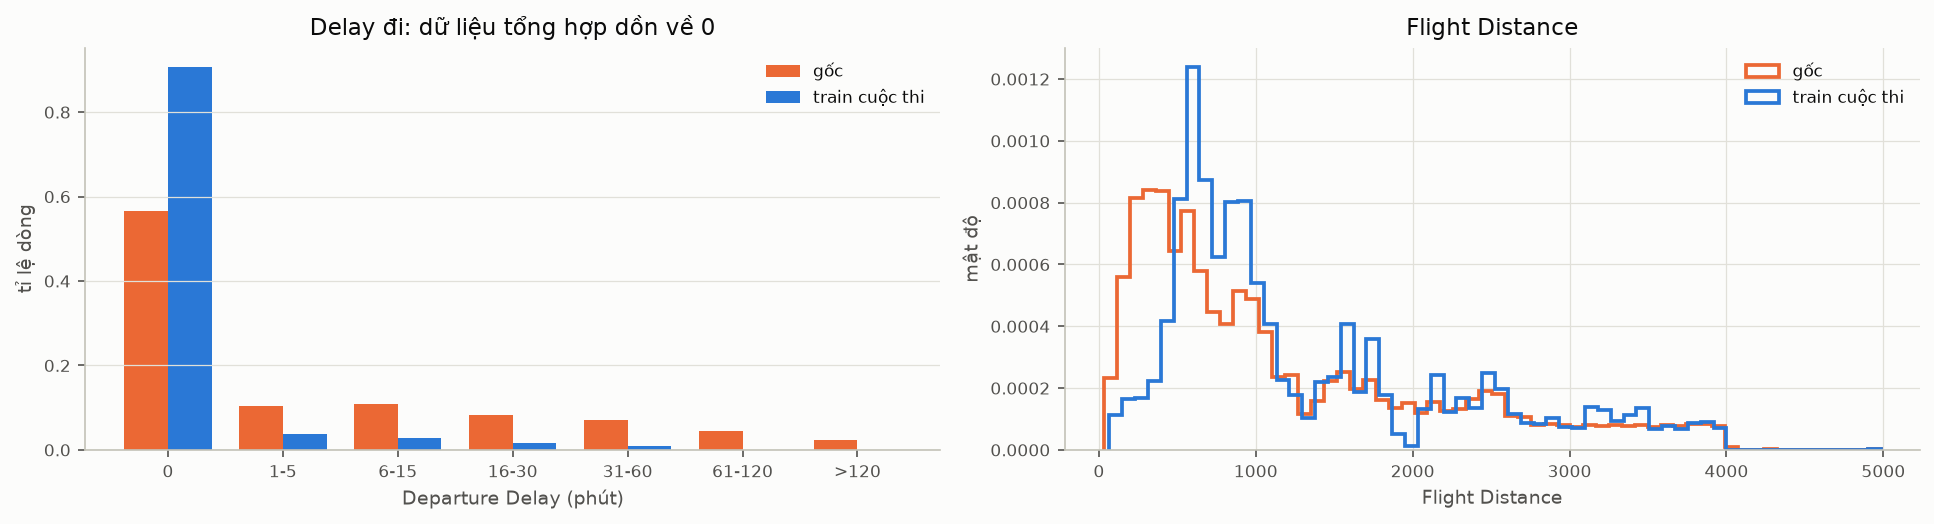

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
bins = [-1, 0, 5, 15, 30, 60, 120, 10_000]
labels = ["0", "1-5", "6-15", "16-30", "31-60", "61-120", ">120"]
w = 0.38
for k_, (df, colr, name) in enumerate([(orig, P.ORANGE, "gốc"), (train, P.BLUE, "train cuộc thi")]):
    s = pd.cut(df[DEP], bins, labels=labels).value_counts(normalize=True).reindex(labels)
    axes[0].bar(np.arange(len(labels)) + (k_ - 0.5) * w, s.values, width=w, color=colr, label=name)
    axes[1].hist(df["Flight Distance"], bins=60, density=True, histtype="step", lw=1.8, color=colr, label=name)
axes[0].set_xticks(range(len(labels)), labels)
axes[0].set_xlabel("Departure Delay (phút)")
axes[0].set_ylabel("tỉ lệ dòng")
axes[0].set_title("Delay đi: dữ liệu tổng hợp dồn về 0")
axes[0].grid(axis="x", visible=False)
axes[0].legend()
axes[1].set_xlabel("Flight Distance")
axes[1].set_ylabel("mật độ")
axes[1].set_title("Flight Distance")
axes[1].legend()
fig.tight_layout()
P.save(fig, "E1_12_original_vs_train")

**Nhận xét mục 7–8**
- Adversarial AUC = 0,4995 và KS giữa train và test ≤ 0,003 ở mọi cột: hai tập cùng phân phối, nên CV trên train
  phản ánh đúng test. Mọi chênh lệch giữa CV và leaderboard sau này là do nhiễu (public LB chỉ có 60 nghìn dòng),
  không do dịch chuyển dữ liệu (phân tích ở E6).
- Dữ liệu gốc (129.880 dòng) giống dữ liệu cuộc thi ở phần lớn cột: tỉ lệ hài lòng 43,5% so với 44,4%, các cột điểm
  có KS ≤ 0,07. Nhưng lệch mạnh ở: delay bằng 0 (56% ở gốc so với 91%), delay q99 (180 so với 30 phút),
  `Flight Distance` (trung vị 844 so với 954, KS 0,22), Eco Plus (7,3% so với 4,3%). Chỉ 17 dòng train trùng hệt
  một dòng gốc, tức bộ sinh dữ liệu không chép dòng.
- Hệ quả: ghép dữ liệu gốc vào huấn luyện phải lưu ý cột delay, chỉ thêm vào phần train của fold (không bao giờ vào
  fold validation), và giữ lại hay không phải quyết bằng CV (E2).

## 9. Tóm tắt và hàm ý cho tiền xử lý (E2)

| Phát hiện | Hàm ý | Kiểm chứng |
| --- | --- | --- |
| Không trùng lặp, `id` không mang thông tin | bỏ `id`, không cần khử trùng | – |
| `Arrival Delay` thiếu 0,04%; 87% dòng có delay đến = delay đi | điền bằng delay đi / median / thêm cờ thiếu | E2: giá trị thiếu |
| Delay dồn về 0 (91%), đuôi dài; IQR không dùng được | log1p, cắt ngưỡng, cờ "có trễ"; không xoá dòng | E2: ngoại lệ, biến đổi |
| Điểm 0 = "không áp dụng", tỉ lệ hài lòng rất khác | one-hot điểm hoặc cờ điểm 0 | E2: mã hoá |
| Quan hệ không đơn điệu (`Age`, 7/13 cột điểm) | rời rạc hoá / one-hot cho mô hình tuyến tính | E2: biến đổi; E3 |
| Tương tác `Type of Travel` × `Class`, `Customer Type` × `Type of Travel` | feature ghép | E2: tạo feature |
| PC1 (AUC 0,880) và cụm KMeans (0,854) mạnh hơn mọi cột đơn | tổng / trung bình điểm, đặc trưng cụm, PCA | E2: tạo feature |
| Đa cộng tuyến mức vừa giữa các cột điểm | chính quy hoá cho LR | E3, E4 |
| Vài cột rất yếu khi đứng riêng | chọn feature bằng CV, không bỏ theo cảm tính | E2: chọn feature |
| Train và test cùng phân phối | tin CV | E0, E6 |
| Dữ liệu gốc lệch ở delay và `Flight Distance` | ghép thận trọng, chỉ vào phần train của fold | E2 |